In [7]:
import os
import glob
import xml.etree.ElementTree as ET
from PIL import Image
from torchvision import transforms, models
from torch.utils.data import Dataset, DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
from collections import Counter

# Paths
base_dir = os.path.expanduser(
    "~/.cache/kagglehub/datasets/andrewmvd/face-mask-detection/versions/1/")
train_image_dir = os.path.join(base_dir, "train")
valid_image_dir = os.path.join(base_dir, "valid")
annotation_dir = os.path.join(base_dir, "annotations")

# Classes mapping
label_map = {"with_mask": 0, "without_mask": 1, "mask_weared_incorrect": 2}

# Step 1: Parse Annotations
def parse_annotations(image_dir, annotation_dir):
    label_counts = Counter()
    data = []
    for xml_file in glob.glob(os.path.join(annotation_dir, "*.xml")):
        tree = ET.parse(xml_file)
        root = tree.getroot()

        filename = root.find("filename").text
        img_path = os.path.join(image_dir, filename)

        # Skip missing images
        if not os.path.exists(img_path):
            print(f"Warning: {img_path} not found. Skipping.")
            continue

        # Assign the most frequent label in the annotation to the entire image
        labels = [obj.find("name").text for obj in root.findall("object") if obj.find("name").text in label_map]
        if labels:
            most_common_label = Counter(labels).most_common(1)[0][0]
            label_counts[most_common_label] += 1
            data.append((img_path, label_map[most_common_label]))
    print("Label distribution:", dict(label_counts))
    return data

# Parse training and validation data
train_data = parse_annotations(train_image_dir, annotation_dir)
valid_data = parse_annotations(valid_image_dir, annotation_dir)

print(f"Training samples: {len(train_data)}")
print(f"Validation samples: {len(valid_data)}")

# Step 2: Define Dataset Class
class MaskDataset(Dataset):
    def __init__(self, data, transform=None):
        self.data = data
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        img_path, label = self.data[idx]
        try:
            image = Image.open(img_path).convert("RGB")
            if self.transform:
                image = self.transform(image)
            return image, label
        except Exception as e:
            print(f"Error loading image {img_path}: {e}")
            # Retry with another sample
            return self.__getitem__((idx + 1) % len(self.data))

# Step 3: Define Transforms
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# Create datasets and dataloaders
train_dataset = MaskDataset(train_data, transform=transform)
valid_dataset = MaskDataset(valid_data, transform=transform)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=4)
valid_loader = DataLoader(valid_dataset, batch_size=32, shuffle=False, num_workers=4)

# Step 4: Define Model
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, len(label_map))  # Output layer for 3 classes
model = model.to(device)

# Step 5: Loss Function and Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Step 6: Train the Model
num_epochs = 10
for epoch in range(num_epochs):
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    print(f"Epoch {epoch+1}/{num_epochs}, Loss: {running_loss/len(train_loader)}")

# Step 7: Validate the Model
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for images, labels in valid_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

print(f"Validation Accuracy: {100 * correct / total}%")

# Save the model
torch.save(model.state_dict(), "mask_detector_model.pth")
print("Model saved as mask_detector_model.pth")


Label distribution: {'with_mask': 569, 'without_mask': 91, 'mask_weared_incorrect': 22}
Label distribution: {'with_mask': 146, 'mask_weared_incorrect': 8, 'without_mask': 17}
Training samples: 682
Validation samples: 171
Epoch 1/10, Loss: 0.5444868437268517
Epoch 2/10, Loss: 0.37470685419711197
Epoch 3/10, Loss: 0.3147376741875302
Epoch 4/10, Loss: 0.23888130790807985
Epoch 5/10, Loss: 0.12378897644918073
Epoch 6/10, Loss: 0.097879570083354
Epoch 7/10, Loss: 0.1691287032921206
Epoch 8/10, Loss: 0.1205470117486336
Epoch 9/10, Loss: 0.09641491710631685
Epoch 10/10, Loss: 0.05436683086339723
Validation Accuracy: 84.7953216374269%
Model saved as mask_detector_model.pth


/tmp/ipykernel_16054/460783831.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load("mask_detector_model.pth"))


Predicted Label: with_mask


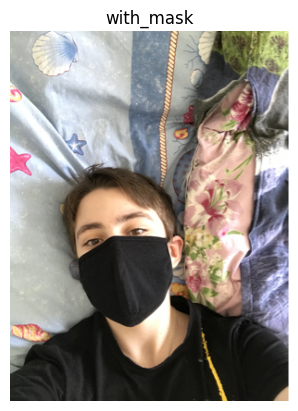

In [10]:
# now using mask_detector_model.pth to predict the mask
# Step 8: Load the Model
import matplotlib.pyplot as plt
model = models.resnet18(pretrained=True)
model.fc = nn.Linear(model.fc.in_features, len(label_map))
model.load_state_dict(torch.load("mask_detector_model.pth"))
model = model
model.eval()

# Step 9: Load the Test Image
test_image_path = os.path.join(base_dir, "valid/maksssksksss4.png")
test_image = Image.open(test_image_path).convert("RGB")
test_image = transform(test_image).unsqueeze(0)

# Step 10: Make Predictions
with torch.no_grad():
    output = model(test_image)
    _, predicted = torch.max(output, 1)
    predicted_label = list(label_map.keys())[predicted.item()]

print(f"Predicted Label: {predicted_label}")

# Step 11: Visualize the Prediction

plt.imshow(Image.open(test_image_path))
plt.title(predicted_label)
plt.axis("off")
plt.show()
